In [176]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import classification_report

In [177]:
dfTrain = pd.read_csv("Titanic_train.csv")
dfTest = pd.read_csv("Titanic_test.csv")

In [178]:
model = LogisticRegression()

In [179]:
dfTrain.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [180]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch']
target = ['Survived']
dfTrainClean = dfTrain[features + target].dropna(subset=features + target)

#Update male and female to 0s and 1s
dfTrainClean['Sex'] = dfTrainClean['Sex'].map({'male':0, 'female':1})

x = dfTrainClean[features]
y = dfTrainClean[target]

In [181]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [182]:
model.fit(x_train, y_train)

c:\Users\mitoc\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [183]:
predictions = model.predict(x_test)

In [184]:
cm = confusion_matrix(y_test, predictions)

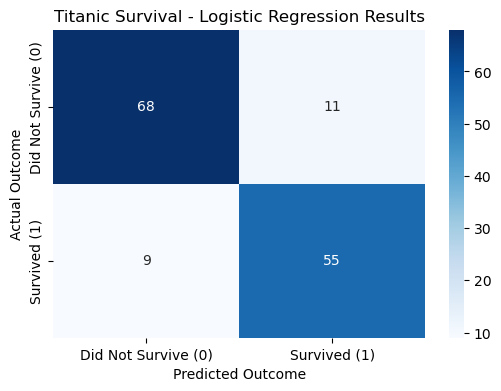

In [185]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Did Not Survive (0)', 'Survived (1)'], 
            yticklabels=['Did Not Survive (0)', 'Survived (1)'])

plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.title('Titanic Survival - Logistic Regression Results')
plt.show()

In [186]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.88      0.86      0.87        79
           1       0.83      0.86      0.85        64

    accuracy                           0.86       143
   macro avg       0.86      0.86      0.86       143
weighted avg       0.86      0.86      0.86       143



In [187]:
# Preparing the data for the Kaggle submission
dfTest.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [188]:
featuresTest = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch']

dfTestClean = dfTest[features].copy()

dfTestClean['Sex'] = dfTestClean['Sex'].map({'male': 0, 'female': 1})

dfTestClean = dfTestClean.fillna(dfTestClean.median())

In [189]:
dfTestClean.head()

,Pclass,Sex,Age,SibSp,Parch
0,3,0,34.5,0,0
1,3,1,47.0,1,0
2,2,0,62.0,0,0
3,3,0,27.0,0,0
4,3,1,22.0,1,1


In [190]:
xTest = dfTestClean[features]

In [191]:
predictionsTest = model.predict(xTest)

In [192]:
submission = pd.DataFrame({
    'PassengerId': dfTest['PassengerId'],
    'Survived': predictionsTest
})

In [193]:
submission.to_csv('submission.csv', index=False)